# 1. One population: a flow on a line (Chapters 1–2)
Model: $\dot a = -a + f(wa + I)$ with $f(x) = 1/(1+e^{-\beta(x-\theta)})$, $w = 10$, $\beta = 1$, $\theta = 5$.

**Picture first.** Steady states are where the S-curve $f(wa+I)$ meets the diagonal $a$. Above the diagonal $a$ grows, below it shrinks.

In [1]:
import numpy as np, matplotlib.pyplot as plt, pyxpp
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.spines.top": False, "axes.spines.right": False})
def load(name, **pars):
    m = pyxpp.load(text=open(f"ode/{name}.ode").read())
    if pars: m.set(**pars)
    return m

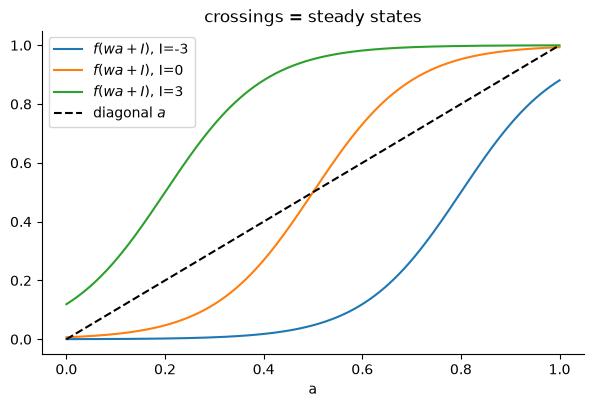

In [2]:
w, beta, th = 10, 1, 5
f = lambda x: 1/(1+np.exp(-beta*(x-th)))
a = np.linspace(0, 1, 400)
for I, c in [(-3, 'C0'), (0, 'C1'), (3, 'C2')]:
    plt.plot(a, f(w*a+I), c, label=f'$f(wa+I)$, I={I}')
plt.plot(a, a, 'k--', label='diagonal $a$'); plt.xlabel('a'); plt.legend(); plt.title('crossings = steady states');

**The S-curve exactly.** Solve $a = f(wa+I)$ for $I$: $I = \theta - \ln(1/a - 1)/\beta - wa$. Stable where $w\beta a(1-a) < 1$.

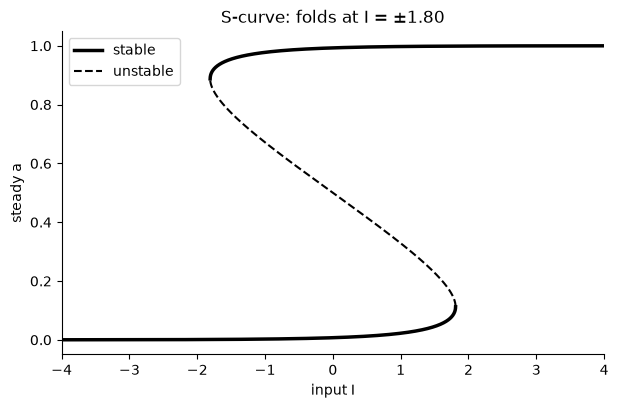

In [3]:
aa = np.linspace(1e-4, 1-1e-4, 3000)
I = th - np.log(1/aa - 1)/beta - w*aa
st = w*beta*aa*(1-aa) < 1
plt.plot(np.where(st, I, np.nan), aa, 'k', lw=2.5, label='stable')
plt.plot(np.where(~st, I, np.nan), aa, 'k--', label='unstable')
plt.xlabel('input I'); plt.ylabel('steady a'); plt.xlim(-4, 4); plt.legend(); plt.title('S-curve: folds at I = ±1.80');

**Hysteresis with XPPAUT.** Ramp $I$ slowly up and down by restarting from the last state at each step.

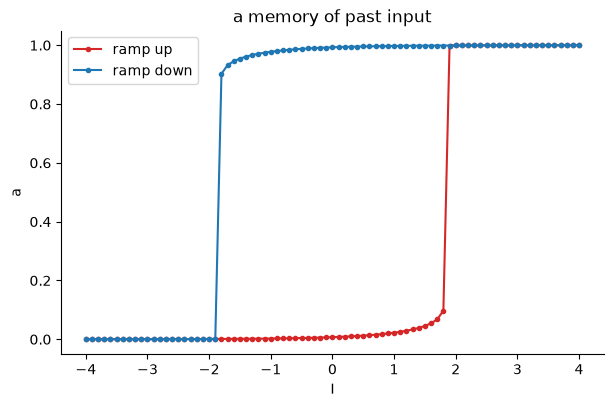

In [4]:
m = load('one_population')
up, dn = [], []
Is = np.linspace(-4, 4, 81)
m.set(i=-4, a=0.0); m.run(total=50)
for I in Is:
    m.set(i=float(I)); m.run_last(total=30); up.append(m.last_point()['A'])
for I in Is[::-1]:
    m.set(i=float(I)); m.run_last(total=30); dn.append(m.last_point()['A'])
plt.plot(Is, up, 'C3o-', ms=3, label='ramp up'); plt.plot(Is[::-1], dn, 'C0o-', ms=3, label='ramp down')
plt.xlabel('I'); plt.ylabel('a'); plt.legend(); plt.title('a memory of past input');

**AUTO** finds the folds directly (continuation of steady states in $I$).

In [5]:
m = load('one_population'); m.set(i=-4, a=0.0); m.run(total=50); m.run_last(total=20)
br = m.auto.run('i', start='steady', ds=0.02, dsmax=0.05, parmin=-4, parmax=4, nmax=2000)
# in one dimension AUTO may label a fold 'BP' instead of 'LP'
pts = sorted({round(p.x, 1) for p in br.special('LP') + br.special('BP') if abs(p.x) < 3.9})
print('folds at I =', pts)

folds at I = [-1.8, 1.8]


**Try:** change `w` to 3 (below the cusp $w = 4/\beta$) and rerun. What happens to the S-curve and the hysteresis?